In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

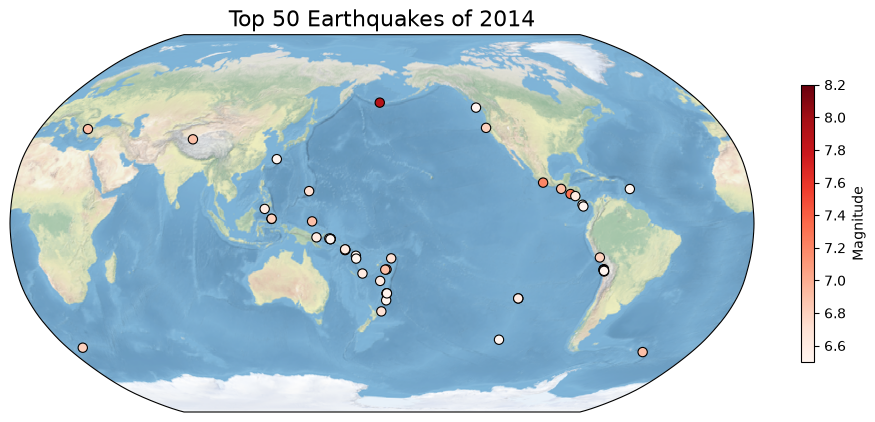

In [3]:
#这是assignment 4-1
# 先从文件里读取数据
df = pd.read_csv("/Users/ruochenliu/Documents/ESE5023/Assignment_4/usgs_earthquakes.csv")

# 筛选震级或者坐标缺失的记录后读取top50强度的地震
top50 = df.dropna(subset=["mag", "longitude", "latitude"]).nlargest(50, "mag")

# 使用 Robinson 投影，以180°经线为地图中心
fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})

# 载入全球范围，然后添加地形背景
ax.set_global()
ax.stock_img()

# 绘制地震位置，颜色表示震级的大小，颜色越深说明震级越大
points = ax.scatter(top50["longitude"], top50["latitude"], c=top50["mag"], cmap="Reds", s=45, edgecolors="black", linewidths=0.8, transform=ccrs.PlateCarree())

# 最后添加颜色条和标题
fig.colorbar(points, ax=ax, label="Magnitude", shrink=0.6)
ax.set_title("Top 50 Earthquakes of 2014", fontsize=16)

plt.show()

In [13]:
#4-2
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from cartopy.util import add_cyclic_point
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


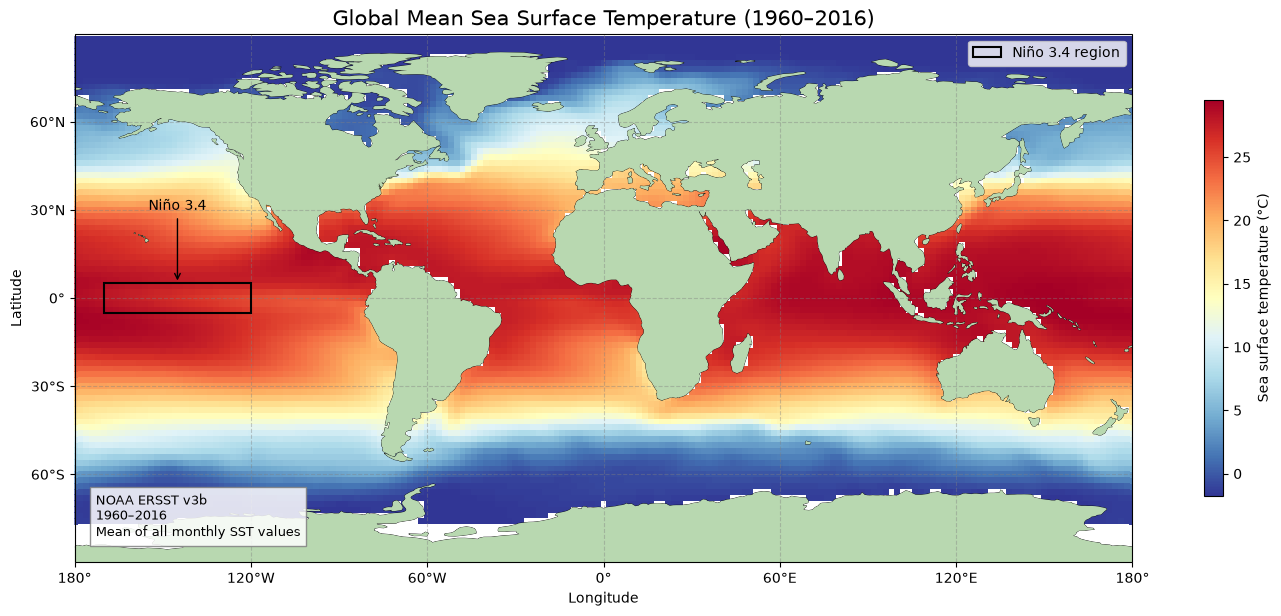

In [20]:
# 先读入海温数据
ds = xr.open_dataset("/Users/ruochenliu/Documents/ESE5023/Assignment_4/NOAA_NCDC_ERSST_v3b_SST.nc")

# 然后把1960—2016年的所有月份取平均
sst_mean = ds["sst"].mean(dim="time")

# 换算经度换成-180°到180°，便于选出Niño 3.4区域 （根据上次作业）
sst_mean = sst_mean.assign_coords(lon=((sst_mean["lon"] + 180) % 360) - 180).sortby("lon")

# 两张图共用同一个颜色范围
vmin = float(sst_mean.min())
vmax = float(sst_mean.max())

#4.2.1
# 在最后补上第一列海温，让全球地图在经度边界处连起来
sst_global, lon_global = add_cyclic_point(sst_mean.values, coord=sst_mean["lon"].values)

# 全球图用等经纬度投影
fig, ax = plt.subplots(figsize=(13, 6), subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
ax.set_global()

# 用不同的颜色表示平均海温
im = ax.pcolormesh(lon_global, sst_mean["lat"], sst_global, cmap="RdYlBu_r", vmin=vmin, vmax=vmax, shading="auto", transform=ccrs.PlateCarree())

# 陆地涂成绿色，再画上海岸线
ax.add_feature(cfeature.LAND, facecolor="#B8D8B0", zorder=2)
ax.coastlines(linewidth=0.5)

# 然后设置经纬度刻度和标签
ax.set_xticks(np.arange(-180, 181, 60), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(-60, 61, 30), crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# 添加上经纬网格线
ax.gridlines(xlocs=np.arange(-180, 181, 60), ylocs=np.arange(-60, 61, 30), linestyle="--", color="gray", alpha=0.4)

# 把上次作业计算Niño 3.4指数的区域框出来
nino_box = Rectangle((-170, -5), 50, 10, facecolor="none", edgecolor="black", linewidth=1.5, transform=ccrs.PlateCarree(), label="Niño 3.4 region", zorder=4)
ax.add_patch(nino_box)
ax.legend(loc="upper right")

# 用箭头指出黑框的位置
ax.annotate("Niño 3.4", xy=(-145, 5), xytext=(-145, 30), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax), ha="center", arrowprops={"arrowstyle": "->"}, fontsize=10, zorder=5)

# 文本框里写上数据来源和时间范围
ax.text(0.02, 0.05, "NOAA ERSST v3b\n1960–2016\nMean of all monthly SST values", transform=ax.transAxes, fontsize=9, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "gray"}, zorder=5)

fig.colorbar(im, ax=ax, label="Sea surface temperature (°C)", shrink=0.75)
ax.set_title("Global Mean Sea Surface Temperature (1960–2016)", fontsize=15)
plt.show()

/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


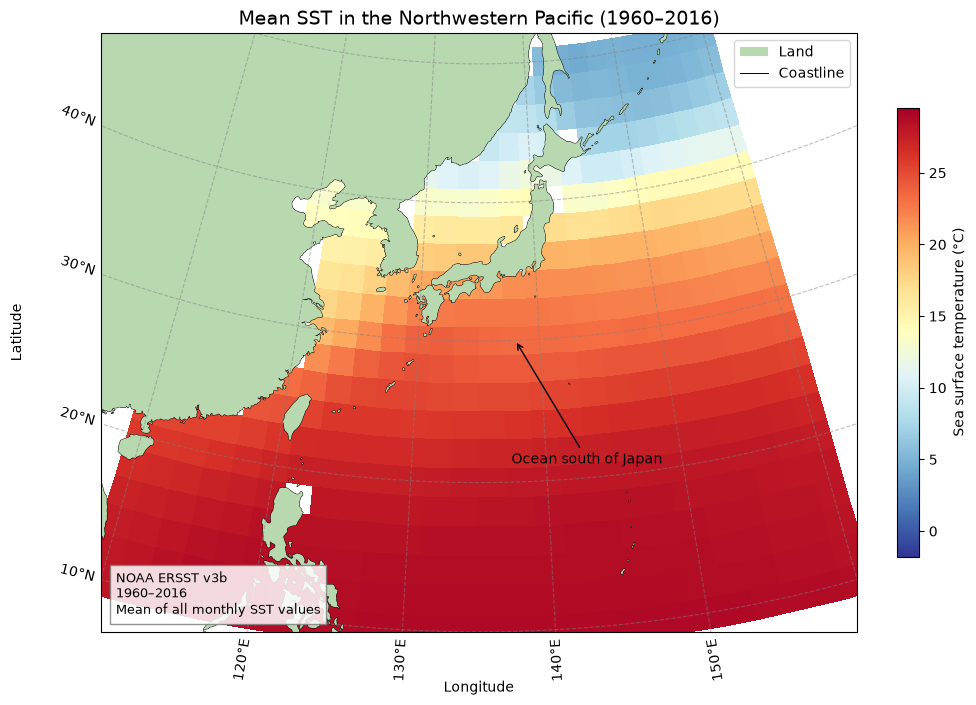

In [22]:
#4.2.2
# 选出西北太平洋区域
sst_region = sst_mean.sel(lon=slice(110, 160), lat=slice(10, 50))

# 区域图用Lambert Conformal投影
projection = ccrs.LambertConformal(central_longitude=135, central_latitude=30)
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw={"projection": projection}, constrained_layout=True)
ax.set_extent([110, 160, 10, 50], crs=ccrs.PlateCarree())

# 画出平均海温，颜色范围和4.2.1全球图一致
im = ax.pcolormesh(sst_region["lon"], sst_region["lat"], sst_region, cmap="RdYlBu_r", vmin=vmin, vmax=vmax, shading="auto", transform=ccrs.PlateCarree())

# 加上灰色陆地和黑色海岸线
ax.add_feature(cfeature.LAND, facecolor="#B8D8B0", zorder=2)
ax.coastlines(linewidth=0.7)

# 显示经纬网格线和刻度数字
gl = ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, xlocs=np.arange(110, 161, 10), ylocs=np.arange(10, 51, 10), x_inline=False, y_inline=False, linestyle="--", color="gray", alpha=0.5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}

# 在图外写上经纬度标签
ax.text(0.5, -0.1, "Longitude", transform=ax.transAxes, ha="center")
ax.text(-0.12, 0.5, "Latitude", transform=ax.transAxes, va="center", rotation=90)

# 图例说明地图上的陆地和海岸线
land_label = Patch(facecolor="#B8D8B0", label="Land")
coast_label = Line2D([0], [0], color="black", linewidth=0.7, label="Coastline")
ax.legend(handles=[land_label, coast_label], loc="upper right")

# 用箭头标出日本南侧的海域
ax.annotate("Ocean south of Japan", xy=(138, 30), xytext=(143, 21), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax), ha="center", arrowprops={"arrowstyle": "->"}, fontsize=10, zorder=5)

# 文本框交代数据来源和时间范围
ax.text(0.02, 0.03, "NOAA ERSST v3b\n1960–2016\nMean of all monthly SST values", transform=ax.transAxes, fontsize=9, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "gray"}, zorder=5)

fig.colorbar(im, ax=ax, label="Sea surface temperature (°C)", shrink=0.75)
ax.set_title("Mean SST in the Northwestern Pacific (1960–2016)", fontsize=14)

plt.show()